In [2]:

# Update this to the path where you put your dataset
DATA_ROOT = "/kaggle/input/bdd100k/bdd100k_10k"   # <- change if needed

# Quick check
import os
print("Root exists:", os.path.exists(DATA_ROOT))
print("Train folder:", os.listdir(os.path.join(DATA_ROOT, "train"))[:10])
print("Test folder:", os.listdir(os.path.join(DATA_ROOT, "test"))[:10])
print("Val folder:", os.listdir(os.path.join(DATA_ROOT, "val"))[:10])

Root exists: True
Train folder: ['ann', 'img']
Test folder: ['ann', 'img']
Val folder: ['ann', 'img']


In [3]:

# Imports
import os, json, math, time
from PIL import Image, ImageDraw, ImageFont
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor


In [4]:
# meta.json is at the dataset root (you pasted its content earlier).
meta_path = os.path.join(DATA_ROOT, "meta.json")
with open(meta_path, 'r') as f:
    meta = json.load(f)

# Create mapping: classId (the numeric id in annotations) -> contiguous label index (1..N)
classid2label = {c['id']: i+1 for i, c in enumerate(meta['classes'])}
label2name = {i+1: c['title'] for i,c in enumerate(meta['classes'])}
print("Classes:", label2name)


Classes: {1: 'bicycle', 2: 'bus', 3: 'car', 4: 'caravan', 5: 'motorcycle', 6: 'pedestrian', 7: 'rider', 8: 'trailer', 9: 'train', 10: 'truck'}


In [5]:
class BDD100KDataset(Dataset):
    def __init__(self, split_root, meta_root, transforms=None):
        """
        split_root: path to train/ or val/ or test/ (the folder that contains 'img' and 'ann')
        meta_root: root where meta.json is located
        """
        self.split_root = split_root
        self.img_dir = os.path.join(split_root, "img")
        self.ann_dir = os.path.join(split_root, "ann")
        self.transforms = transforms

        # list image filenames (without extension handling if needed)
        self.img_files = [f for f in sorted(os.listdir(self.img_dir)) if f.lower().endswith(('.jpg','.png'))]

        # load class mapping from meta.json
        with open(os.path.join(meta_root, "meta.json"), 'r') as f:
            m = json.load(f)
        self.classid2label = {c['id']: i+1 for i,c in enumerate(m['classes'])}

    def __len__(self):
        return len(self.img_files)

    def _get_bbox_from_obj(self, obj):
        pts = obj['points']['exterior']
        if obj['geometryType'] == "rectangle" and len(pts) >= 2:
            x1,y1 = pts[0]
            x2,y2 = pts[1]
            xmin, xmax = min(x1,x2), max(x1,x2)
            ymin, ymax = min(y1,y2), max(y1,y2)
        else:
            xs = [p[0] for p in pts]
            ys = [p[1] for p in pts]
            xmin, xmax = min(xs), max(xs)
            ymin, ymax = min(ys), max(ys)
        return [xmin, ymin, xmax, ymax]

    def __getitem__(self, idx):
        img_name = self.img_files[idx]
        img_path = os.path.join(self.img_dir, img_name)
        ann_path = os.path.join(self.ann_dir, img_name + ".json")
        image = Image.open(img_path).convert("RGB")

        boxes = []
        labels = []
        # some files might be missing an annotation file
        if os.path.exists(ann_path):
            with open(ann_path, 'r') as f:
                ann = json.load(f)
            for obj in ann.get('objects', []):
                class_id = obj.get('classId')
                if class_id not in self.classid2label:
                    continue  # skip unknown classes
                bbox = self._get_bbox_from_obj(obj)
                # skip degenerate boxes
                if bbox[2] <= bbox[0] or bbox[3] <= bbox[1]:
                    continue
                boxes.append(bbox)
                labels.append(self.classid2label[class_id])

        # convert to tensors in the format FasterRCNN expects
        boxes = torch.as_tensor(boxes, dtype=torch.float32) if boxes else torch.zeros((0,4), dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64) if labels else torch.zeros((0,), dtype=torch.int64)
        image_id = torch.tensor([idx])

        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        target["image_id"] = image_id
        target["area"] = (boxes[:,3] - boxes[:,1]) * (boxes[:,2] - boxes[:,0]) if boxes.shape[0] else torch.zeros((0,))
        target["iscrowd"] = torch.zeros((boxes.shape[0],), dtype=torch.int64)

        if self.transforms:
            image = self.transforms(image)

        return image, target


In [6]:
# Simple transforms: convert PIL to tensor
def get_transform(train):
    transforms = []
    transforms.append(T.ToTensor())
    return T.Compose(transforms)

train_dataset = BDD100KDataset(os.path.join(DATA_ROOT, "train"), DATA_ROOT, transforms=get_transform(True))
val_dataset   = BDD100KDataset(os.path.join(DATA_ROOT, "val"), DATA_ROOT, transforms=get_transform(False))

# small batch (GPU memory)
def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True, num_workers=2, collate_fn=collate_fn)
val_loader   = DataLoader(val_dataset, batch_size=1, shuffle=False, num_workers=2, collate_fn=collate_fn)

In [7]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

# load pretrained model
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True)

# replace box predictor
num_classes = len(meta['classes']) + 1   # +1 for background
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

model.to(device)


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth
100%|██████████| 160M/160M [00:00<00:00, 189MB/s]  


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

# optimizer & scheduler
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

num_epochs = 5   # start small to verify everything works

for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0.0
    t0 = time.time()
    for images, targets in train_loader:
        images = list(img.to(device) for img in images)
        targets = [{k: v.to(device) for k,v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        epoch_loss += losses.item()
    lr_scheduler.step()
    print(f"Epoch {epoch+1}/{num_epochs}  loss: {epoch_loss:.4f}  time: {time.time()-t0:.1f}s")


In [8]:
from tqdm import tqdm
import time

# optimizer & scheduler
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

num_epochs = 5
train_losses = []
val_losses = []
epoch_times = []

for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0.0
    t0 = time.time()

    # ---- Training Progress Bar ----
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}", leave=False)
    for images, targets in pbar:
        images = list(img.to(device) for img in images)
        targets = [{k: v.to(device) for k,v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        epoch_loss += losses.item()
        pbar.set_postfix({"batch_loss": f"{losses.item():.4f}"})

    avg_train_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # ---- Validation ----
    model.eval()
    val_epoch_loss = 0.0
    with torch.no_grad():
        for images, targets in val_loader:
            images = list(img.to(device) for img in images)
            targets = [{k: v.to(device) for k,v in t.items()} for t in targets]
            
            # Calculate validation loss by temporarily enabling training mode
            model.train()
            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())
            val_epoch_loss += losses.item()
            model.eval()  # Switch back to evaluation mode

    avg_val_loss = val_epoch_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    # ---- Record time ----
    epoch_time = time.time() - t0
    epoch_times.append(epoch_time)

    # ---- Print Epoch Summary with ETA ----
    elapsed = sum(epoch_times)
    remaining = (num_epochs - (epoch+1)) * (elapsed / (epoch+1))
    print(f"✅ Epoch {epoch+1}/{num_epochs} | "
          f"Train: {avg_train_loss:.4f} | Val: {avg_val_loss:.4f} | "
          f"Time: {epoch_time:.1f}s | ETA: ~{remaining/60:.1f} min left")

    lr_scheduler.step()

✅ Epoch 1/5 | Train: 0.8841 | Val: 0.8123 | Time: 2499.1s | ETA: ~166.6 min left


✅ Epoch 2/5 | Train: 0.7832 | Val: 0.8040 | Time: 2517.5s | ETA: ~125.4 min left


✅ Epoch 3/5 | Train: 0.7418 | Val: 0.7867 | Time: 2520.2s | ETA: ~83.7 min left


✅ Epoch 4/5 | Train: 0.6338 | Val: 0.7373 | Time: 2523.5s | ETA: ~41.9 min left


✅ Epoch 5/5 | Train: 0.6068 | Val: 0.7396 | Time: 2524.0s | ETA: ~0.0 min left


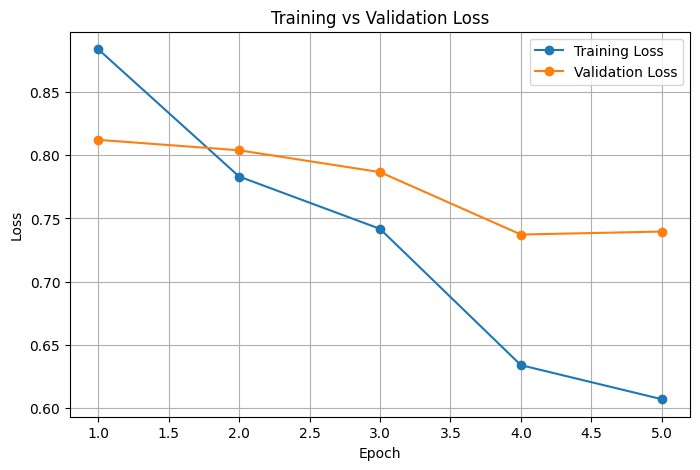

In [9]:
import matplotlib.pyplot as plt

# After training finishes
plt.figure(figsize=(8,5))
plt.plot(range(1, num_epochs+1), train_losses, label="Training Loss", marker="o")
plt.plot(range(1, num_epochs+1), val_losses, label="Validation Loss", marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
import matplotlib.pyplot as plt
import numpy as np

def draw_boxes(image_pil, boxes, labels, scores=None, score_thresh=0.5):
    draw = ImageDraw.Draw(image_pil)
    for i, box in enumerate(boxes):
        score = scores[i] if scores is not None else 1.0
        if score < score_thresh:
            continue
        xmin, ymin, xmax, ymax = box
        label = label2name.get(int(labels[i]), str(labels[i]))
        draw.rectangle([xmin, ymin, xmax, ymax], outline="red", width=2)
        draw.text((xmin+3, ymin+3), f"{label}:{score:.2f}", fill="yellow")
    return image_pil

In [11]:
# Instead of writing into DATA_ROOT (read-only), write into /kaggle/working
test_img_dir = os.path.join(DATA_ROOT, "test", "img")
out_dir = os.path.join("/kaggle/working", "preds")  # writable folder
os.makedirs(out_dir, exist_ok=True)

model.eval()
with torch.no_grad():
    for fname in sorted(os.listdir(test_img_dir)):
        if not fname.lower().endswith((".jpg",".png")):
            continue
        path = os.path.join(test_img_dir, fname)
        img = Image.open(path).convert("RGB")
        img_t = T.ToTensor()(img).to(device)
        outputs = model([img_t])[0]
        boxes = outputs['boxes'].cpu().numpy()
        labels = outputs['labels'].cpu().numpy()
        scores = outputs['scores'].cpu().numpy()
        img_out = img.copy()
        img_out = draw_boxes(img_out, boxes, labels, scores, score_thresh=0.5)
        save_path = os.path.join(out_dir, fname)
        img_out.save(save_path)

print("Saved predictions to:", out_dir)


Saved predictions to: /kaggle/working/preds


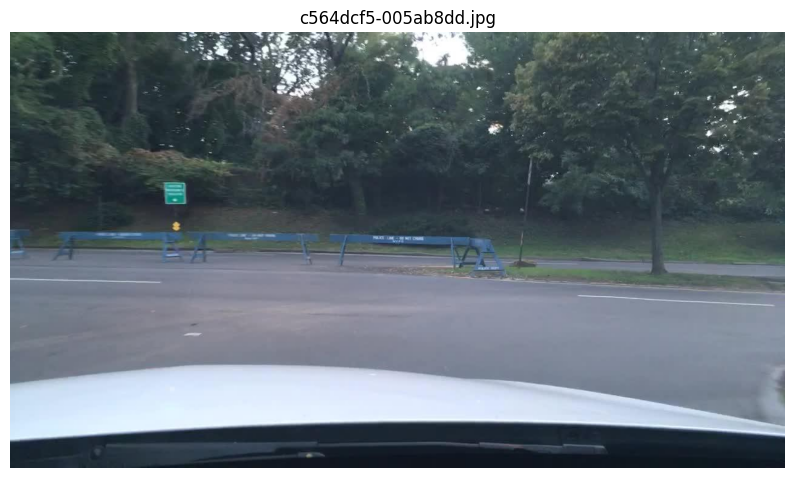

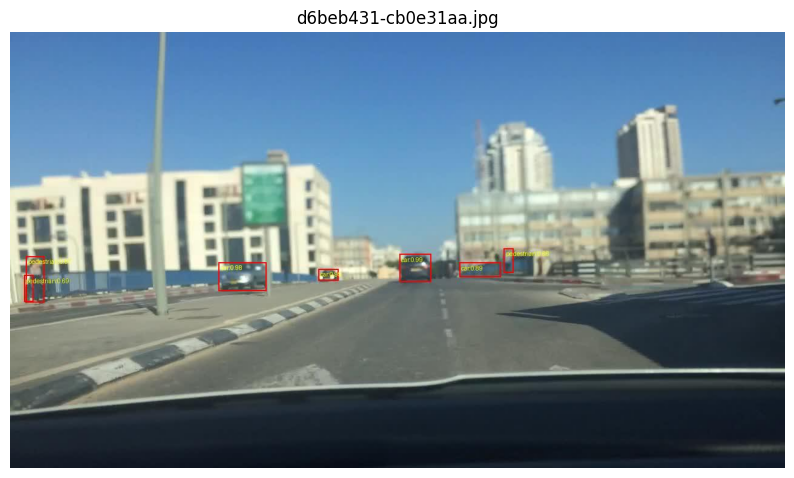

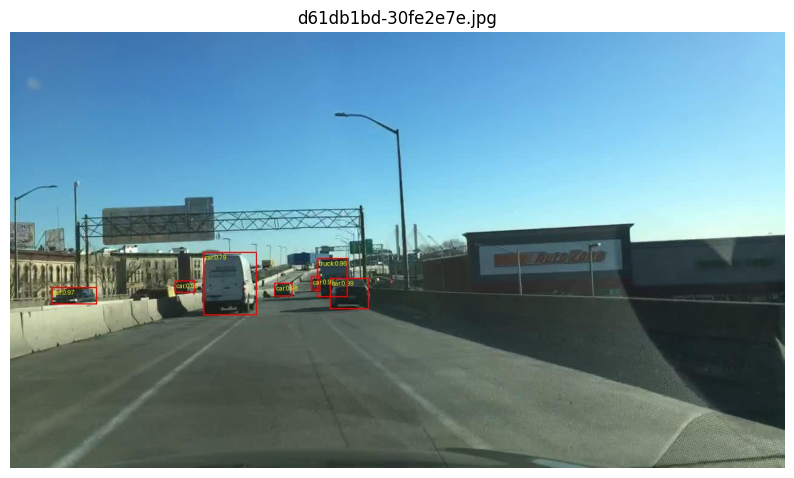

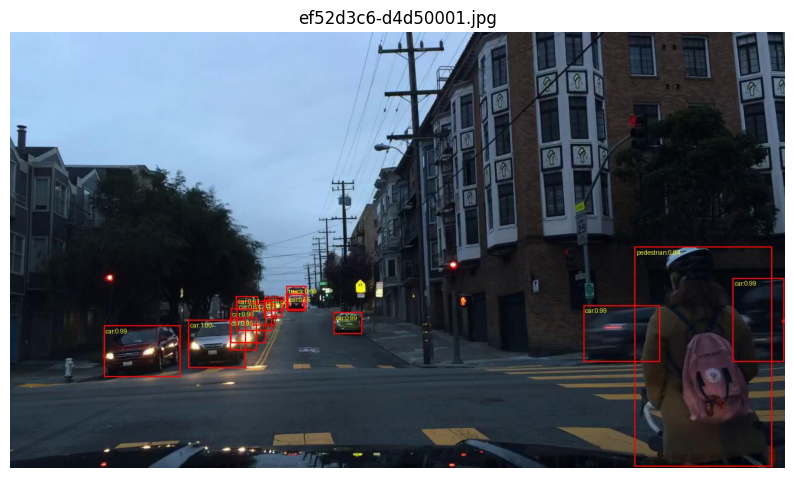

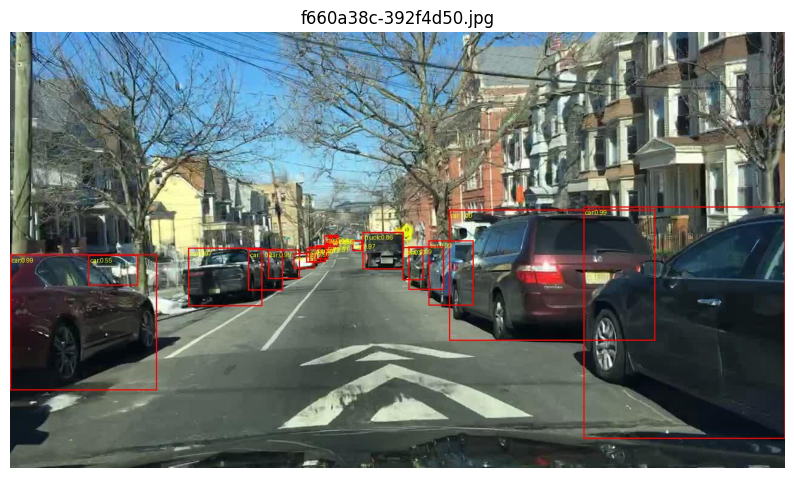

In [12]:
import matplotlib.pyplot as plt
import random
import os
from PIL import Image

# Path where predictions were saved
pred_dir = "/kaggle/working/preds"

# Pick random images
pred_files = [f for f in os.listdir(pred_dir) if f.lower().endswith((".jpg", ".png"))]
sample_files = random.sample(pred_files, min(5, len(pred_files)))  # show up to 5

for fname in sample_files:
    img_path = os.path.join(pred_dir, fname)
    img = Image.open(img_path)

    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.title(fname)
    plt.show()


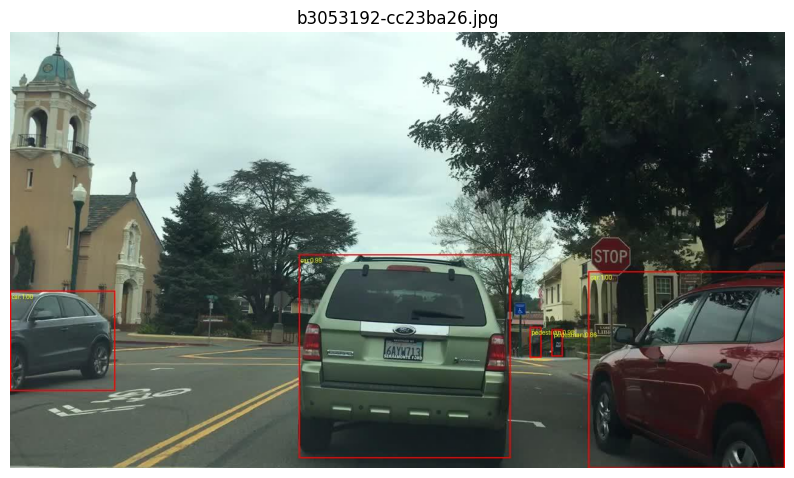

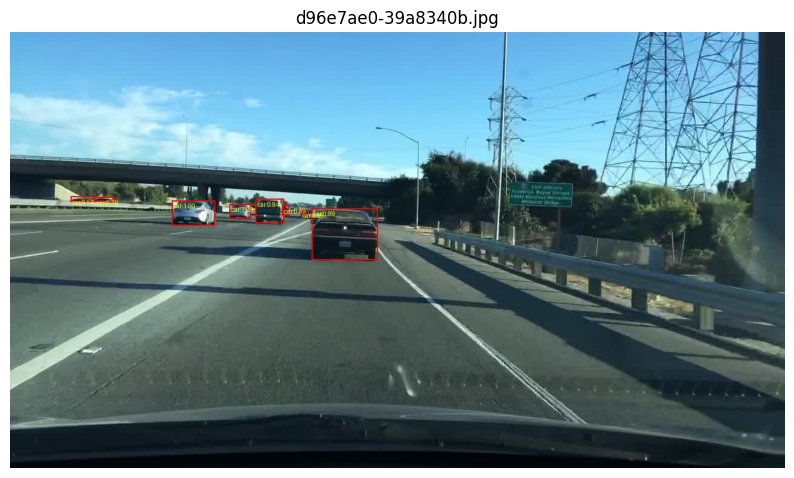

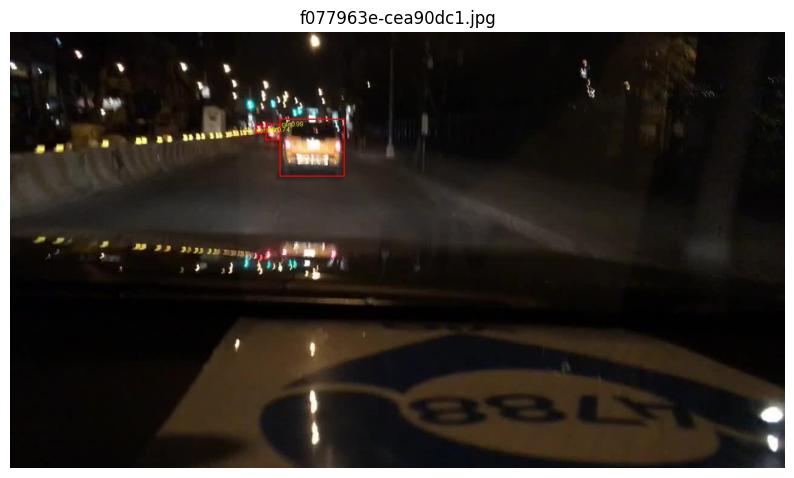

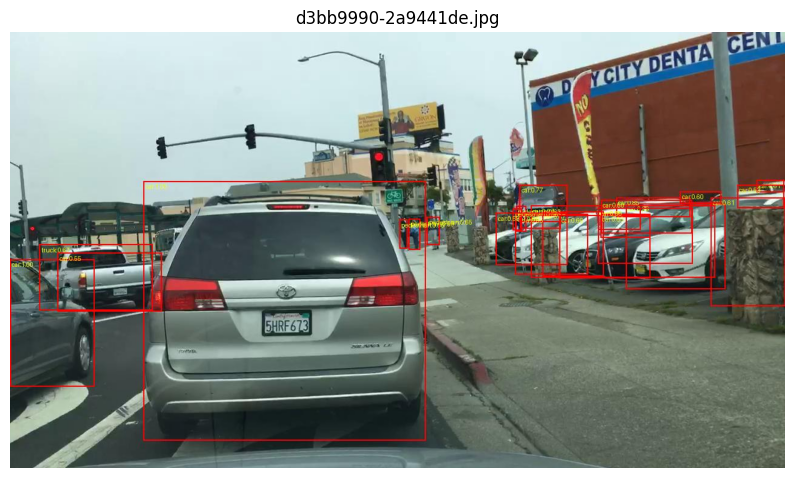

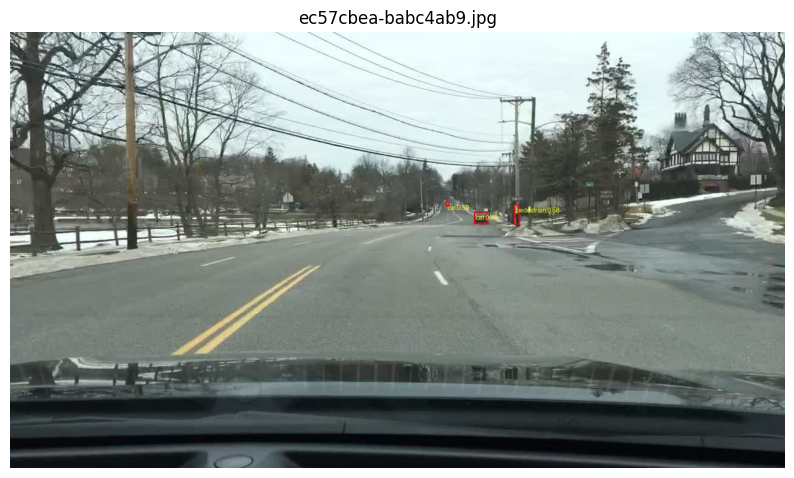

In [13]:
import matplotlib.pyplot as plt
import random
import os
from PIL import Image, ImageDraw, ImageFont

# Class names from meta.json
CLASS_NAMES = [
    "bicycle", "bus", "car", "caravan", "motorcycle",
    "pedestrian", "rider", "trailer", "train", "truck"
]

# Color palette (class-specific)
COLORS = [
    "#0082C8", "#F032E6", "#E6194B", "#911EB4", "#F58230",
    "#3CB44B", "#FABED4", "#46F0F0", "#DCBEFF", "#FFE119"
]

def draw_boxes_with_labels(image, boxes, labels, scores, score_thresh=0.5):
    draw = ImageDraw.Draw(image)

    # Bigger font: 5% of image height
    font_size = max(14, int(image.height * 0.09))
    try:
        font = ImageFont.truetype("DejaVuSans.ttf", font_size)
    except:
        font = ImageFont.load_default()

    for box, label, score in zip(boxes, labels, scores):
        if score < score_thresh:
            continue
        color = COLORS[label % len(COLORS)]
        box = [int(b) for b in box]

        # Draw bounding box
        draw.rectangle(box, outline=color, width=3)

        # Create label text
        text = f"{CLASS_NAMES[label-1]} {score:.2f}"
        text_size = draw.textsize(text, font=font)

        # Draw filled rectangle behind text
        text_bg = [box[0], box[1] - text_size[1], box[0] + text_size[0], box[1]]
        draw.rectangle(text_bg, fill=color)

        # Draw text
        draw.text((box[0], box[1] - text_size[1]), text, fill="black", font=font)

    return image


# Show random predictions
def show_random_predictions(pred_dir, num_images=5):
    pred_files = [f for f in os.listdir(pred_dir) if f.lower().endswith((".jpg", ".png"))]
    sample_files = random.sample(pred_files, min(num_images, len(pred_files)))

    for fname in sample_files:
        img_path = os.path.join(pred_dir, fname)
        img = Image.open(img_path).convert("RGB")

        plt.figure(figsize=(10, 8))
        plt.imshow(img)
        plt.axis("off")
        plt.title(fname)
        plt.show()

# Example usage
pred_dir = "/kaggle/working/preds"
show_random_predictions(pred_dir, num_images=5)


In [25]:
model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for images, targets in val_loader:
        images = [img.to(device) for img in images]
        outputs = model(images)

        for out, tgt in zip(outputs, targets):
            gt_labels = tgt["labels"].cpu().numpy()
            y_true.extend(gt_labels)

            if len(out["labels"]) > 0:
                # take top-k predictions (here = 1 per GT)
                pred_labels = out["labels"].cpu().numpy()
                pred_scores = out["scores"].cpu().numpy()

                # sort by confidence
                sorted_idx = pred_scores.argsort()[::-1]
                pred_labels = pred_labels[sorted_idx]

                # only keep same number as ground truth
                if len(pred_labels) >= len(gt_labels):
                    y_pred.extend(pred_labels[:len(gt_labels)])
                else:
                    # not enough predictions → pad with background (0)
                    y_pred.extend(list(pred_labels) + [0]*(len(gt_labels)-len(pred_labels)))
            else:
                # no predictions, assign background
                y_pred.extend([0]*len(gt_labels))


In [26]:
metrics = classification_metrics(y_true, y_pred, labels=list(label2name.keys()))
print("Accuracy:", metrics["accuracy"])
print("Precision:", metrics["precision"])
print("Recall:", metrics["recall"])
print("Confusion Matrix:\n", metrics["confusion_matrix"])


Accuracy: 0.7278698541205224
Precision: 0.7480697532960973
Recall: 0.7278698541205224
Confusion Matrix:
 [[   28     5   106     0     4    57     2     0     0    11]
 [    3    27   302     1     0    69     2     0     0    25]
 [  102   309 18190     5    83  1788    63     0     0  1001]
 [    0     2    80     1     1    16     0     0     0     5]
 [    1     1    77     0     2     9     2     0     0     4]
 [   32    60  1442     1    15   697    12     0     0   106]
 [    3     0    62     0     3    19     2     0     0     2]
 [    0     0    11     0     0     1     0     0     0     2]
 [    0     0    12     0     0     2     0     0     0     0]
 [    5    27   779     0     4   104     5     0     0   113]]


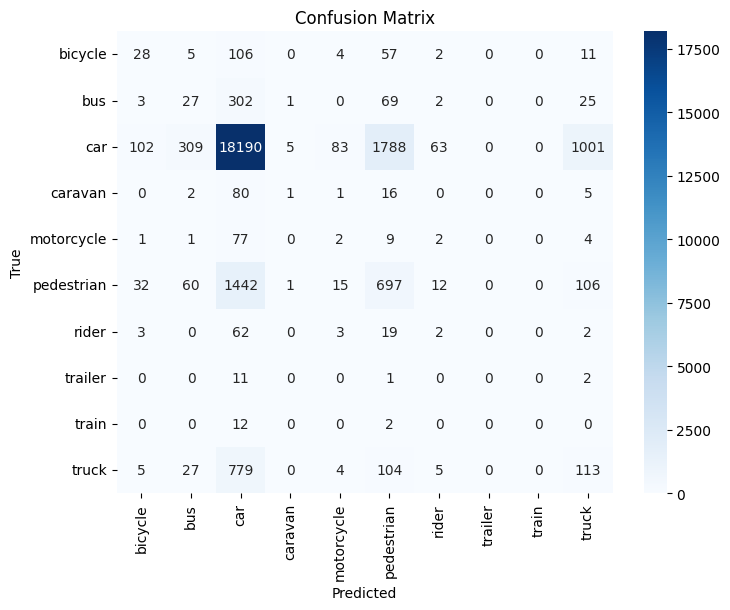

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_confusion_matrix(cm, labels, title="Confusion Matrix"):
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
                xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

# Example usage:
metrics = classification_metrics(y_true, y_pred, labels=list(label2name.keys()))
cm = metrics["confusion_matrix"]

plot_confusion_matrix(cm, labels=list(label2name.values()))
